# Simulation: recoverability of RS/OF tuning-ellipse orientation

Positive control for the orientation distribution of Fig 3K-M (motorized wheel),
complementing the circular null of Fig S7D. Every neuron of the Fig 3K population keeps its
real trial-average plateau Gaussian (amplitude, centre, offset, both sigmas, hence its real
elongation) but its major axis is rotated to a known angle. Its dF/F is simulated along the
real RS/OF trajectory (biexponential kernel, as in Fig S7), its own circularly shifted
residual is added as noise, and it is refitted with the real trial-average plateau
configuration. Four ground truths, plus the circular control already in the paper:

| scenario | true angles | question |
|---|---|---|
| `circular` | none (major axis reduced to the minor, as Fig S7D) | is elongation or tri-modality created by calcium dynamics / fitting? Noise seed -1 is the Fig S7D control itself |
| `ratio45` | all 45° | can a single ratio-tuned population produce the 0°/90° modes? |
| `cardinal` | 50% 0°, 50% 90° | can RS- or OF-tuned cells be pulled to 45°? |
| `uniform` | uniform on [-45°, 135°) | true → recovered transfer function, attractors, error vs elongation |
| `matched` | drawn from the Fig 3M mixture | is a real tri-modal distribution recovered (k, weights)? |

Fits are made by `precompute_data/fit_revision_simulation_recovery.py` (one parquet per
session; noise seed -1 is noise-free, 0..9 are independent residual shifts, the angles are
the same for every seed). Population: significant trial-average g2d fit and depth-tuned in
closed loop (Fig 3K). Orientation statistics use the same 1.4:1 elongation cut, bins and
axial von Mises mixture (k by BIC, seed 42) as Fig 3M.

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import flexiznam as flz

from cottage_analysis.analysis import fit_gaussian_blob as fit_gb
from cottage_analysis.plotting import style
from cottage_analysis.plotting.style import CM, FONTSIZE_DICT

from v1_depth_map.paths import get_figures_roots
from v1_depth_map.figure_utils import von_mises as vm
from v1_depth_map.figure_utils.rsof_integration import plot_angle_eccentricity_polar
from v1_depth_map.precompute_data.fit_revision_simulation_recovery import (
    SCENARIOS,
    ELONGATION_CUTOFF,
    VM_MAX_K,
    VM_SEED,
    output_filename,
    session_dir,
    wrap_axial_deg,
)
from v1_depth_map.precompute_data.fit_revision_treadmill import SESSIONS, MIN_SIGMA

style.setup_figure_fonts()
fontsize_dict = FONTSIZE_DICT

## Load the simulated fits

In [ ]:
project = "colasa_3d-vision_revisions"
flexilims_session = flz.get_flexilims_session(project)
READ_ROOT, SAVE_ROOT = get_figures_roots(flexilims_session)
SAVE_ROOT.mkdir(parents=True, exist_ok=True)

# Noise seed shown in the example panels; the others give the across-seed statistics.
EXAMPLE_SEED = 2
SCENARIO_LABELS = {
    "circular": "Circular (Fig S7D)",
    "ratio45": "All 45°",
    "cardinal": "50% 0°, 50% 90°",
    "uniform": "Uniform",
    "matched": "Matched to data",
}

parts = []
for session in SESSIONS:
    df = pd.read_parquet(session_dir(session) / output_filename())
    df["session"] = session
    parts.append(df)
sim = pd.concat(parts, ignore_index=True)


def elongation(popt):
    return fit_gb.get_semimajor_length(popt, min_sigma=MIN_SIGMA) / fit_gb.get_semiminor_length(
        popt, min_sigma=MIN_SIGMA
    )


with np.errstate(over="ignore", invalid="ignore"):
    sim["rec_angle"] = sim.popt_simulated.apply(fit_gb.get_gaussian_angle)
    sim["rec_elongation"] = sim.popt_simulated.apply(elongation)
# Signed axial error in [-90, 90): recovered minus true orientation.
sim["err"] = (sim.rec_angle - sim.true_angle + 90) % 180 - 90
sim["elong_ok"] = sim.rec_elongation > ELONGATION_CUTOFF

# The real Fig 3K-M population, carried in the parquet, for reference.
real = sim[(sim.scenario == SCENARIOS[0]) & (sim.noise_seed == EXAMPLE_SEED)][
    ["roi_uid", "real_angle", "real_elongation"]
]
real_ok = real.real_elongation > ELONGATION_CUTOFF

noise_seeds = sorted(sim.noise_seed.unique())
print(
    f"{sim.roi_uid.nunique()} neurons, {sim.session.nunique()} sessions, "
    f"scenarios {list(SCENARIOS)}, noise seeds {noise_seeds}"
)
print(f"real data: {int(real_ok.sum())}/{len(real)} with elongation > {ELONGATION_CUTOFF}")

285 neurons, 4 sessions, scenarios ['circular', 'ratio45', 'cardinal', 'uniform', 'matched'], noise seeds [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
real data: 266/285 with elongation > 1.4


## Orientation mixtures

Same axial von Mises mixture and BIC selection as Fig 3M, on the elongated recovered fits,
for every scenario and noise seed (and for the real data, which reproduces Fig 3M).

In [ ]:
def fit_mixture(angles_deg):
    res = vm.model_selection(
        np.radians(np.asarray(angles_deg, dtype=float)), max_k=VM_MAX_K, seed=VM_SEED, verbose=False
    )
    k = min(res, key=lambda kk: res[kk]["bic"])
    r = res[k]
    return dict(
        k=int(k),
        pi_k=np.asarray(r["pi_k"], float),
        mu_k=np.asarray(r["mu_k"], float),
        kappa_k=np.asarray(r["kappa_k"], float),
        bic={kk: res[kk]["bic"] for kk in res},
    )


def describe(mix):
    mu = wrap_axial_deg(np.degrees(mix["mu_k"]))
    order = np.argsort(mu)
    return ", ".join(f"{mu[i]:.0f}° ({100 * mix['pi_k'][i]:.0f}%)" for i in order)


mix_real = fit_mixture(real.loc[real_ok, "real_angle"])
print(f"real data: k={mix_real['k']}: {describe(mix_real)}")

mixtures = {}
for scen in SCENARIOS:
    for seed in noise_seeds:
        d = sim[(sim.scenario == scen) & (sim.noise_seed == seed) & sim.elong_ok]
        mixtures[(scen, seed)] = fit_mixture(d.rec_angle)
    # Reference: the same mixture fit on the ground truth of the same (elongated) cells.
    # `circular` has no true orientation.
    d = sim[(sim.scenario == scen) & (sim.noise_seed == EXAMPLE_SEED) & sim.elong_ok]
    has_truth = d.true_angle.notna().all()
    mixtures[(scen, "truth")] = fit_mixture(d.true_angle) if has_truth else None
    m, mt = mixtures[(scen, EXAMPLE_SEED)], mixtures[(scen, "truth")]
    if mt is not None:
        print(f"{scen:9s} truth:   k={mt['k']}: {describe(mt)}")
    print(f"{scen:9s} seed {EXAMPLE_SEED}: k={m['k']}: {describe(m)}")

real data: k=3: 3° (14%), 43° (76%), 90° (11%)
circular  seed 1: k=1: 76° (100%)
ratio45   truth:   k=1: 45° (100%)
ratio45   seed 1: k=2: 46° (29%), 46° (71%)
cardinal  truth:   k=2: 0° (48%), 90° (52%)
cardinal  seed 1: k=3: -3° (22%), 4° (32%), 90° (46%)
uniform   truth:   k=1: -4° (100%)
uniform   seed 1: k=1: 22° (100%)
matched   truth:   k=3: 5° (15%), 45° (69%), 89° (16%)
matched   seed 1: k=3: 5° (10%), 44° (78%), 88° (12%)


## Summary table

`near45` / `near_card`: fraction of elongated fits within 22.5° of 45° / of 0° or 90°
(22.5° is half the distance between the ratio and cardinal hypotheses, the resolution used
to justify the 1.4:1 cut in Fig 3), for the ground truth and the recovered fits.
`frac_elongated`: fraction of fits above the 1.4:1 cut (for `circular` with noise seed -1
this is the Fig S7D number, on the Fig 3K population). `k_truth`: BIC-selected k on the ground-truth angles of the same cells; `k_seeds`: how
often each k was selected over the noise seeds.

In [ ]:
def axial_dist(a, b):
    return np.abs((np.asarray(a, dtype=float) - b + 90) % 180 - 90)


def near45(a):
    a = np.asarray(a, dtype=float)
    return np.nan if np.isnan(a).all() else (axial_dist(a, 45) < 22.5).mean()


def near_card(a):
    a = np.asarray(a, dtype=float)
    if np.isnan(a).all():
        return np.nan
    return ((axial_dist(a, 0) < 22.5) | (axial_dist(a, 90) < 22.5)).mean()


rows = []
for scen in SCENARIOS:
    for seed in noise_seeds:
        d = sim[(sim.scenario == scen) & (sim.noise_seed == seed)]
        ok = d[d.elong_ok]
        rows.append(
            dict(
                scenario=scen,
                noise_seed=seed,
                n=len(d),
                n_elongated=len(ok),
                frac_elongated=len(ok) / len(d),
                median_abs_err=np.median(np.abs(ok.err)),
                frac_err_lt_22_5=(np.abs(ok.err) < 22.5).mean() if ok.err.notna().all() else np.nan,
                near45_truth=near45(ok.true_angle),
                near45_rec=near45(ok.rec_angle),
                near_card_truth=near_card(ok.true_angle),
                near_card_rec=near_card(ok.rec_angle),
                best_k=mixtures[(scen, seed)]["k"],
            )
        )
summary = pd.DataFrame(rows)
noisy = summary[summary.noise_seed >= 0]

table = noisy.groupby("scenario", sort=False).median(numeric_only=True).drop(
    columns=["noise_seed", "best_k"]
)
table["noise_free_median_abs_err"] = (
    summary[summary.noise_seed < 0].set_index("scenario").median_abs_err
)
table["noise_free_frac_elongated"] = (
    summary[summary.noise_seed < 0].set_index("scenario").frac_elongated
)
table["k_truth"] = [
    mixtures[(s, "truth")]["k"] if mixtures[(s, "truth")] else np.nan for s in table.index
]
table["k_seeds"] = [
    dict(sorted(noisy[noisy.scenario == s].best_k.value_counts().to_dict().items()))
    for s in table.index
]
print(f"medians over {noisy.noise_seed.nunique()} noise seeds")
with pd.option_context("display.width", 250, "display.precision", 3, "display.max_columns", 20):
    print(table.T)

real_angles = real.loc[real_ok, "real_angle"]
print(
    f"\nreal data (elongated): near45 {near45(real_angles):.1%}, "
    f"near_card {near_card(real_angles):.1%}, k={mix_real['k']}, "
    f"elongated {real_ok.mean():.1%}"
)

medians over 10 noise seeds
scenario                  circular       ratio45      cardinal  uniform       matched
n                            285.0         285.0         285.0    285.0         285.0
n_elongated                  164.5         269.5         264.5    260.5         267.0
frac_elongated               0.577         0.946         0.928    0.914         0.937
median_abs_err                 NaN          4.21         4.536    5.974         4.868
frac_err_lt_22_5               NaN         0.924         0.913    0.879         0.923
near45_truth                   NaN           1.0           0.0    0.253         0.508
near45_rec                   0.295         0.924         0.046    0.284         0.472
near_card_truth                NaN           0.0           1.0    0.487         0.485
near_card_rec                0.526         0.068         0.924    0.512         0.503
noise_free_median_abs_err      NaN         0.702         2.954    2.118         1.655
noise_free_frac_elongated 

## Figure 1: ground truth vs recovered orientation, one column per scenario

Drawn for noise seed 0 and for the noise-free fits (`noise_seed = -1`; for `circular`
this is the Fig S7D control). Top: recovered orientation and elongation, polar axes as in Fig 3K; dark red
are fits below the 1.4:1 cut. Bottom: orientation histogram of the elongated recovered fits
(grey), the ground truth of the same neurons (black outline; none for `circular`) and the
best-BIC axial von Mises mixture (curve), as in Fig 3M.

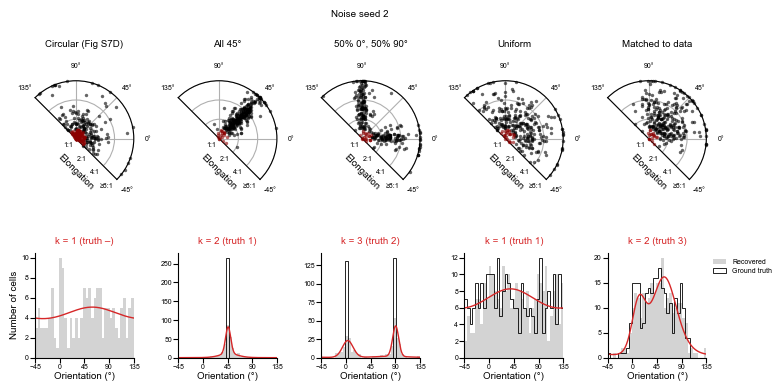

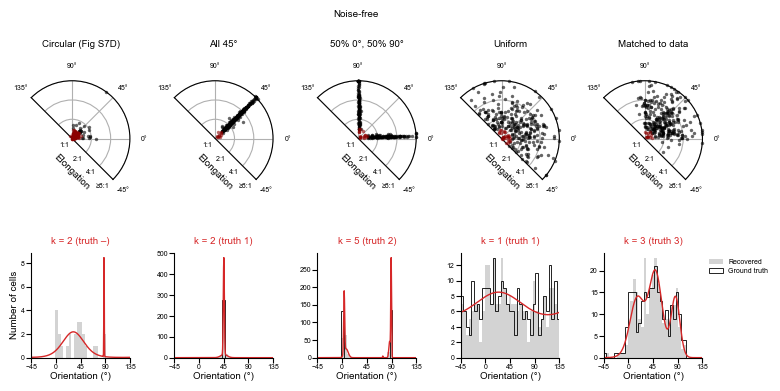

In [ ]:
N_ANGLE_BINS = 37  # as in Fig 3M
angle_edges = np.linspace(-45, 135, N_ANGLE_BINS + 1)
angle_bin_w = np.diff(angle_edges)[0]
angle_grid = np.linspace(-45, 135, 400)
POLAR_IN_COLOR, POLAR_OUT_COLOR = "k", "darkred"
sc_kwargs = dict(s=6, alpha=0.6, linewidths=0, clip_on=False, zorder=3)

def plot_scenarios(seed):
    # One column per scenario for one noise seed (-1: noise-free).
    fig = plt.figure(figsize=(22 * CM, 9.5 * CM))
    gs = fig.add_gridspec(2, len(SCENARIOS), height_ratios=[1.15, 1], hspace=0.55, wspace=0.45)

    for icol, scen in enumerate(SCENARIOS):
        d = sim[(sim.scenario == scen) & (sim.noise_seed == seed)]
        ok = d.elong_ok

        pax = fig.add_subplot(gs[0, icol], projection="polar")
        plot_angle_eccentricity_polar(
            pax,
            d.loc[ok, "rec_angle"].astype(float),
            None,
            fontsize_dict,
            radial_scale="elongation",
            axis_ratio=d.loc[ok, "rec_elongation"],
            schematics=False,
            c=POLAR_IN_COLOR,
            **sc_kwargs,
        )
        pax.scatter(
            np.radians(d.loc[~ok, "rec_angle"].astype(float)),
            np.clip(np.log2(d.loc[~ok, "rec_elongation"].astype(float)), 0, None),
            c=POLAR_OUT_COLOR,
            **sc_kwargs,
        )
        pax.set_title(SCENARIO_LABELS[scen], fontsize=fontsize_dict["title"], pad=12)

        hax = fig.add_subplot(gs[1, icol])
        hax.hist(
            d.loc[ok, "rec_angle"],
            bins=angle_edges,
            color="lightgrey",
            edgecolor="none",
            label="Recovered",
        )
        if d.true_angle.notna().all():
            hax.hist(
                d.loc[ok, "true_angle"],
                bins=angle_edges,
                histtype="step",
                color="k",
                lw=0.6,
                label="Ground truth",
            )
        mix = mixtures[(scen, seed)]
        to_counts = ok.sum() * angle_bin_w
        dens = vm.axial_mixture_density(np.radians(angle_grid), mix["pi_k"], mix["mu_k"], mix["kappa_k"])
        hax.plot(angle_grid, dens / np.degrees(1) * to_counts, color="C3", lw=1)
        hax.set_xlim(-45, 135)
        hax.set_xticks([-45, 0, 45, 90, 135])
        hax.set_xlabel("Orientation (°)", fontsize=fontsize_dict["label"])
        if icol == 0:
            hax.set_ylabel("Number of cells", fontsize=fontsize_dict["label"])
        if icol == len(SCENARIOS) - 1:  # last column has both histograms
            hax.legend(fontsize=fontsize_dict["legend"], frameon=False, loc="upper left",
                       bbox_to_anchor=(1.0, 1.0))
        mt = mixtures[(scen, "truth")]
        hax.set_title(
            f"k = {mix['k']} (truth {mt['k'] if mt else '–'})",
            fontsize=fontsize_dict["title"],
            color="C3",
        )
        hax.tick_params(labelsize=fontsize_dict["tick"], pad=1)
        sns.despine(ax=hax)

    fig.suptitle("Noise-free" if seed < 0 else f"Noise seed {seed}",
                 fontsize=fontsize_dict["title"], y=1.04)
    return fig


for seed, sfx in ((EXAMPLE_SEED, ""), (-1, "_noise_free")):
    fig = plot_scenarios(seed)
    style.savefig(SAVE_ROOT / f"fig_reviewer_simulation_recovery_scenarios{sfx}.svg", fig=fig,
                  bbox_inches="tight", transparent=True)

## Figure 2: transfer function, error vs elongation, model selection across noise seeds

A. `uniform` scenario, noise seed 0: recovered against true orientation (elongated fits).
Recovered is plotted as true + axial error, so a perfect recovery lies on the diagonal.
B. Median absolute orientation error against the neuron's true elongation (`uniform`,
pooled over noise seeds; bins with < 10 neurons not drawn), noise-free vs noisy; dashed line: 22.5°, dotted line: the 1.4:1
cut. C. Number of components chosen by BIC across the noise seeds, per scenario (dot area
= number of seeds); open circles: k of the ground truth; dashed line: k of the real data
(Fig 3M).

PosixPath('/Volumes/BlackPasspo/v1_depth_map/processed/v1_manuscript_figures/ver_rev1/fig_reviewer_simulation_recovery_transfer.svg')

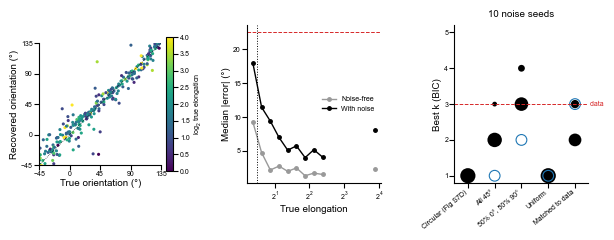

In [ ]:
fig2, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(18 * CM, 5.2 * CM),
                                        gridspec_kw=dict(wspace=0.55))

# A. transfer function
d = sim[(sim.scenario == "uniform") & (sim.noise_seed == EXAMPLE_SEED) & sim.elong_ok]
sca = ax_a.scatter(d.true_angle, d.true_angle + d.err, c=np.log2(d.real_elongation.clip(upper=2**4)),
                   cmap="viridis", s=5, lw=0, vmin=0, vmax=4)
ax_a.plot([-45, 135], [-45, 135], color="k", lw=0.5, ls=":")
for ax_lim in (ax_a.set_xlim, ax_a.set_ylim):
    ax_lim(-45, 135)
ax_a.set_xticks([-45, 0, 45, 90, 135])
ax_a.set_yticks([-45, 0, 45, 90, 135])
ax_a.set_aspect("equal")
ax_a.set_xlabel("True orientation (°)", fontsize=fontsize_dict["label"])
ax_a.set_ylabel("Recovered orientation (°)", fontsize=fontsize_dict["label"])
cb = fig2.colorbar(sca, ax=ax_a, fraction=0.05, pad=0.04)
cb.set_label("log$_2$ true elongation", fontsize=fontsize_dict["legend"])
cb.ax.tick_params(labelsize=fontsize_dict["tick"])

# B. error vs true elongation
d = sim[sim.scenario == "uniform"].copy()
el_edges = 2 ** np.arange(0, 4.01, 0.25)
d["el_bin"] = pd.cut(d.real_elongation.clip(upper=el_edges[-1] - 1e-9), el_edges)
centres = np.sqrt(el_edges[:-1] * el_edges[1:])
MIN_BIN_CELLS = 10  # distinct neurons per bin; sparser bins are not drawn
for label, mask, color in (
    ("Noise-free", d.noise_seed < 0, "0.6"),
    ("With noise", d.noise_seed >= 0, "k"),
):
    grp = d[mask].groupby("el_bin", observed=False)
    n_cells = grp.roi_uid.nunique()
    med = grp.err.apply(lambda e: np.median(np.abs(e))).where(n_cells >= MIN_BIN_CELLS)
    ax_b.plot(centres, med.values, "o-", color=color, ms=2.5, lw=1, label=label)
ax_b.axhline(22.5, color="C3", ls="--", lw=0.7)
ax_b.axvline(ELONGATION_CUTOFF, color="k", ls=":", lw=0.7)
ax_b.set_xscale("log", base=2)
ax_b.set_xlabel("True elongation", fontsize=fontsize_dict["label"])
ax_b.set_ylabel("Median |error| (°)", fontsize=fontsize_dict["label"])
ax_b.legend(fontsize=fontsize_dict["legend"], frameon=False)

# C. best k across noise seeds
ks = np.arange(1, VM_MAX_K + 1)
for i, scen in enumerate(SCENARIOS):
    counts = noisy[noisy.scenario == scen].best_k.value_counts().reindex(ks, fill_value=0)
    ax_c.scatter(np.full(len(ks), i), ks, s=counts.values * 12, color="k", lw=0)
    if mixtures[(scen, "truth")]:
        ax_c.scatter(i, mixtures[(scen, "truth")]["k"], s=60, facecolor="none",
                     edgecolor="C0", lw=0.8)
ax_c.axhline(mix_real["k"], color="C3", ls="--", lw=0.7)
ax_c.text(len(SCENARIOS) - 0.5, mix_real["k"], " data", color="C3", va="center",
          fontsize=fontsize_dict["legend"])
ax_c.set_xticks(range(len(SCENARIOS)))
ax_c.set_xticklabels([SCENARIO_LABELS[s] for s in SCENARIOS], rotation=40, ha="right")
ax_c.set_yticks(ks)
ax_c.set_xlim(-0.5, len(SCENARIOS) - 0.5)
ax_c.set_ylabel("Best k (BIC)", fontsize=fontsize_dict["label"])
ax_c.set_title(f"{noisy.noise_seed.nunique()} noise seeds", fontsize=fontsize_dict["title"])

for ax in (ax_a, ax_b, ax_c):
    ax.tick_params(labelsize=fontsize_dict["tick"], pad=1)
    sns.despine(ax=ax)

style.savefig(SAVE_ROOT / "fig_reviewer_simulation_recovery_transfer.svg", fig=fig2,
              bbox_inches="tight", transparent=True)

## Supplementary: every noise seed of one scenario

Orientation histograms of the elongated recovered fits for each noise seed (noise-free
first), as in the bottom row of Figure 1, with the best-BIC mixture (red) and each of its
components (dashed, labelled with mean and weight). Shows what the extra components BIC
adds for the sharply peaked `cardinal` and `ratio45` ground truths are fitting.

PosixPath('/Volumes/BlackPasspo/v1_depth_map/processed/v1_manuscript_figures/ver_rev1/fig_reviewer_simulation_recovery_seeds_cardinal.svg')

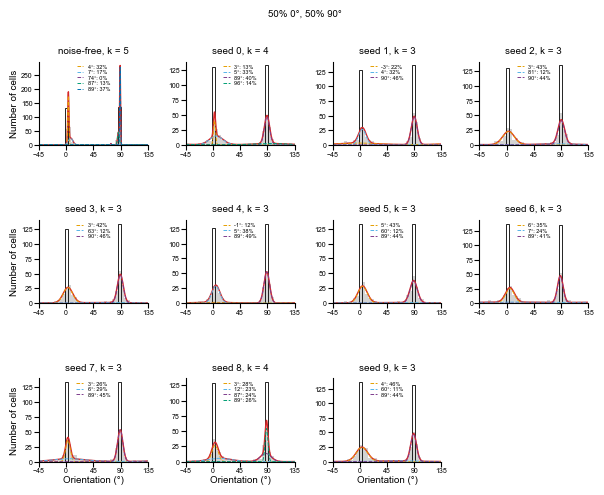

In [ ]:
SEED_PANEL_SCENARIO = "cardinal"
COMPONENT_COLORS = ("#E69F00", "#56B4E9", "#7F3C8D", "#009E73", "#0072B2")


def plot_seed_histograms(scen, ncols=4):
    seeds = noise_seeds
    nrows = int(np.ceil(len(seeds) / ncols))
    fig_s, axes = plt.subplots(nrows, ncols, figsize=(18 * CM, 4.4 * CM * nrows),
                               squeeze=False, gridspec_kw=dict(hspace=0.9, wspace=0.35))
    for ax, seed in zip(axes.flat, seeds):
        d = sim[(sim.scenario == scen) & (sim.noise_seed == seed) & sim.elong_ok]
        ax.hist(d.rec_angle, bins=angle_edges, color="lightgrey", edgecolor="none")
        if d.true_angle.notna().all():
            ax.hist(d.true_angle, bins=angle_edges, histtype="step", color="k", lw=0.6)
        mix = mixtures[(scen, seed)]
        to_counts = len(d) * angle_bin_w / np.degrees(1)
        grid = np.radians(angle_grid)
        ax.plot(angle_grid,
                vm.axial_mixture_density(grid, mix["pi_k"], mix["mu_k"], mix["kappa_k"]) * to_counts,
                color="C3", lw=1)
        mu = wrap_axial_deg(np.degrees(mix["mu_k"]))
        for rank, i in enumerate(np.argsort(mu)):
            ax.plot(angle_grid,
                    vm.axial_mixture_density(grid, mix["pi_k"][[i]], mix["mu_k"][[i]],
                                             mix["kappa_k"][[i]]) * to_counts,
                    color=COMPONENT_COLORS[rank % len(COMPONENT_COLORS)], lw=0.7, ls="--",
                    label=f"{mu[i]:.0f}°: {100 * mix['pi_k'][i]:.0f}%")
        ax.set_title(("noise-free" if seed < 0 else f"seed {seed}") + f", k = {mix['k']}",
                     fontsize=fontsize_dict["title"])
        ax.legend(fontsize=fontsize_dict["legend"] - 1, frameon=False, loc="upper center",
                  handlelength=1.2, borderpad=0, labelspacing=0.1)
        ax.set_xlim(-45, 135)
        ax.set_xticks([-45, 0, 45, 90, 135])
        ax.tick_params(labelsize=fontsize_dict["tick"], pad=1)
        sns.despine(ax=ax)
    for ax in axes.flat[len(seeds):]:
        ax.axis("off")
    for ax in axes[:, 0]:
        ax.set_ylabel("Number of cells", fontsize=fontsize_dict["label"])
    for ax in axes[-1]:
        ax.set_xlabel("Orientation (°)", fontsize=fontsize_dict["label"])
    fig_s.suptitle(SCENARIO_LABELS[scen], fontsize=fontsize_dict["title"])
    return fig_s


fig_seeds = plot_seed_histograms(SEED_PANEL_SCENARIO)
style.savefig(SAVE_ROOT / f"fig_reviewer_simulation_recovery_seeds_{SEED_PANEL_SCENARIO}.svg",
              fig=fig_seeds, bbox_inches="tight", transparent=True)